I will be using the load_breast_cancer library from sklearn.datasets to use a simple logistic regression model to do binary classification on whether a patient has breast cancer (melignant) or does not have breast cancer (benign)

In [14]:
from sklearn.datasets import load_breast_cancer
import numpy as np
import pandas as pd
data = load_breast_cancer()
features = data.data
labels = data.target
df = pd.DataFrame(features, columns=data.feature_names)
df['has_cancer'] = labels


We need to change the target column because malignant was labeled as 0 and benign was 1, but our confusion matrix expects 1 to be positive and 0 to be negative

In [15]:
df['target'] = (df['has_cancer']==0).astype(int)
df = df.drop(columns='has_cancer')


In [16]:
#splitting into features and target
X = df.drop('target', axis=1)
y = df['target']

Now we need to seperate the training values from testing values and stratify on the targets so there is same amount of positive values, important for classification

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

I'm pretty sure this data is pretty clean but I'm going to perform some EDA on it to get a better insight

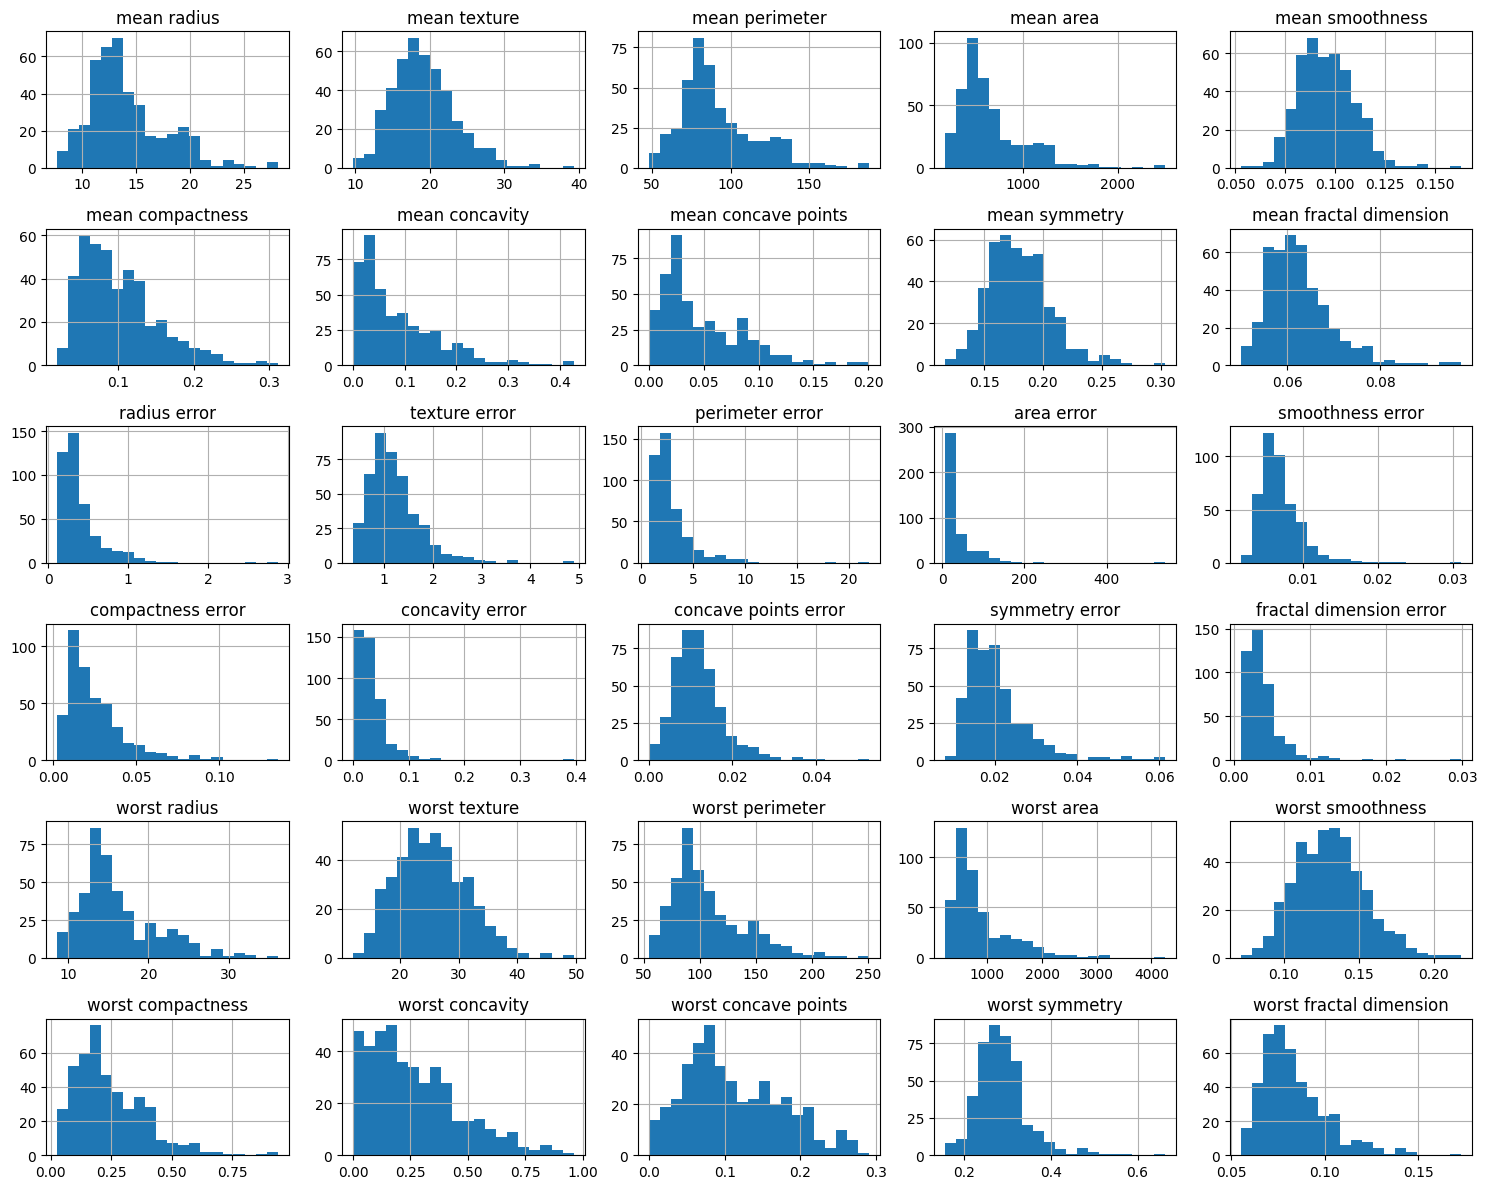

In [18]:
#looking at histograms for all the features
import matplotlib.pyplot as plt
X_train.hist(bins=20, figsize=(15,12))
plt.tight_layout()
plt.show()

From the histograms above I'm going to try to normalize the mean_area, mean_compactness, mean_concavity, mean_concavity_points, radius_error,texture_error,perimiter_error,area_error,smothness_error

In [19]:
from sklearn.preprocessing import FunctionTransformer
#creating a custom transformer to take the log of the data to normalize
log_transformer = FunctionTransformer(np.log)



Now lets create a pipeline to scale the data and then train using logistic regression model and also a pipeline for the log

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
process_skew = Pipeline([
    ('log', log_transformer),
    ('scale', StandardScaler())
])
logged_cols = ['mean area','mean compactness','mean concavity','mean concave points','radius error','texture error','perimeter error','area error','smoothness error']
#all other feature transformations are scaling
remainer_transform = Pipeline([
    ('scale', StandardScaler())
])
processed = ColumnTransformer([
    ('pre_process', process_skew, logged_cols)
], remainder=remainer_transform)

predictor = Pipeline([
    ('pre', processed),
    ('model', LogisticRegression())
])

Now we are going to use the cross validation predict function to get an array of predictions for each fold so that we are not running a prediction on values it trained from. Then, we will use those to plug into our confusion matrix to get a true sense of the accuracy of the model

In [21]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
predictions_arr = cross_val_predict(predictor, X_train, y_train, cv=5) #5 folded cv
cm = confusion_matrix(y_true=y_train, y_pred=predictions_arr)
cm_plt = ConfusionMatrixDisplay(cm)
cm_plt.plot()



c:\Users\stevi\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\internals\blocks.py:347: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)


ValueError: Input X contains infinity or a value too large for dtype('float64').

Using our confusion matrix lets get the accuracy data 

In [11]:
from sklearn.metrics import recall_score, precision_score, f1_score
recall = recall_score(y_true=y_train, y_pred=predictions_arr) #percentage of positive identified from FN and TP
precision = precision_score(y_true=y_train, y_pred=predictions_arr) #percentage of correct positive from TP and FP
f1 = f1_score(y_true=y_train, y_pred=predictions_arr)
f1

0.9646302250803859

In our model we got a 96% F1 score for the confusion matrix which is very good. This shows our model is classifying correctly and it is around even for recall and precission. This means it is finding the true positive values often and also getting a good percentage for the number of values it finds positive.